In [1]:
!pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo

# Load German Credit Dataset
german_credit = fetch_ucirepo(id=144)

# Separate features and target
X = german_credit.data.features
y = german_credit.data.targets

# Display dataset
print("Dataset Loaded Successfully!")
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

# Show first 5 rows
print(X.head())

Dataset Loaded Successfully!
Features Shape: (1000, 20)
Target Shape: (1000, 1)
  Attribute1  Attribute2 Attribute3 Attribute4  Attribute5 Attribute6  \
0        A11           6        A34        A43        1169        A65   
1        A12          48        A32        A43        5951        A61   
2        A14          12        A34        A46        2096        A61   
3        A11          42        A32        A42        7882        A61   
4        A11          24        A33        A40        4870        A61   

  Attribute7  Attribute8 Attribute9 Attribute10  Attribute11 Attribute12  \
0        A75           4        A93        A101            4        A121   
1        A73           2        A92        A101            2        A121   
2        A74           2        A93        A101            3        A121   
3        A74           2        A93        A103            4        A122   
4        A73           3        A93        A101            4        A124   

   Attribute13 Attribute

In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Check missing values
print("Missing Values:")
print(X.isnull().sum().sum())

# Separate numerical and categorical columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = X.select_dtypes(include=['object', 'category']).columns

print("Numerical Columns:", len(numerical_cols))
print("Categorical Columns:", len(categorical_cols))

# Convert target into binary values
y = y.iloc[:, 0] if isinstance(y, pd.DataFrame) else y

y = y.replace({1: 0, 2: 1})

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Data Preprocessing Completed Successfully!")

Missing Values:
0
Numerical Columns: 7
Categorical Columns: 13
Training Data: (800, 20)
Testing Data: (200, 20)
Data Preprocessing Completed Successfully!


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# Create models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

# Train and evaluate models
for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    print("\nModel:", name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1 Score:", f1_score(y_test, y_pred))
    print("ROC-AUC:", roc_auc_score(y_test, y_prob))

    print("----------------------------")


Model: Logistic Regression
Accuracy: 0.78
Precision: 0.6666666666666666
Recall: 0.5333333333333333
F1 Score: 0.5925925925925926
ROC-AUC: 0.8040476190476191
----------------------------

Model: Decision Tree
Accuracy: 0.63
Precision: 0.3793103448275862
Recall: 0.36666666666666664
F1 Score: 0.3728813559322034
ROC-AUC: 0.5547619047619048
----------------------------

Model: Random Forest
Accuracy: 0.74
Precision: 0.6052631578947368
Recall: 0.38333333333333336
F1 Score: 0.46938775510204084
ROC-AUC: 0.7792857142857142
----------------------------


In [5]:
import joblib

# Store trained models
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, y_prob)

    trained_models[name] = {
        'pipeline': pipeline,
        'roc_auc': auc
    }

# Select best model
best_model_name = max(
    trained_models,
    key=lambda name: trained_models[name]['roc_auc']
)

best_model = trained_models[best_model_name]['pipeline']

print("Best Model:", best_model_name)
print("ROC-AUC Score:", trained_models[best_model_name]['roc_auc'])

# Save model
joblib.dump(best_model, 'credit_scoring_model.pkl')

print("Model Saved Successfully!")

Best Model: Logistic Regression
ROC-AUC Score: 0.8040476190476191
Model Saved Successfully!


Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.89      0.85       140
           1       0.67      0.53      0.59        60

    accuracy                           0.78       200
   macro avg       0.74      0.71      0.72       200
weighted avg       0.77      0.78      0.77       200



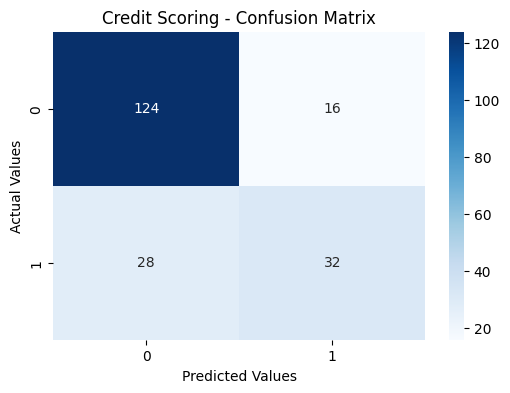

Model Evaluation Completed Successfully!


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

# Predict using best model
y_pred = best_model.predict(X_test)

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Credit Scoring - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

print("Model Evaluation Completed Successfully!")

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.78,0.666667,0.533333,0.592593,0.804048
1,Decision Tree,0.63,0.379310,0.366667,0.372881,0.554762
2,Random Forest,0.74,0.605263,0.383333,0.469388,0.779286


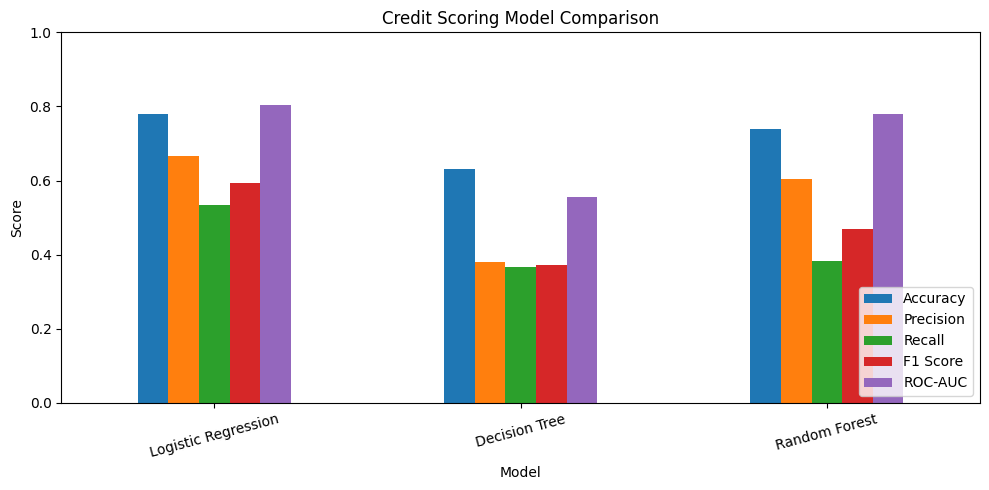

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

results = []

for name, details in trained_models.items():
    pipeline = details['pipeline']
    predictions = pipeline.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1 Score': f1_score(y_test, predictions),
        'ROC-AUC': details['roc_auc']
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(results_df)

results_df.set_index('Model').plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Credit Scoring Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [9]:
# Save model comparison results
results_df.to_csv('credit_scoring_results.csv', index=False)

print("Results Saved Successfully!")

Results Saved Successfully!


In [10]:
from google.colab import files

files.download('credit_scoring_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
files.download('credit_scoring_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>